<a href="https://colab.research.google.com/github/ryouy/GraduationThesis/blob/main/1017/MidPoster_Fig2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fig. 2 — Preliminary Results (Mann-style pilot)

This notebook exports a **poster-ready, editable SVG** showing the target-word mention rates under related and unrelated cue conditions (one distractor block). The default data are embedded at the top and do not require an Internet connection.

- **Original run:** `Qwen/Qwen2.5-0.5B-Instruct`, 8 target concepts, 5 generations per concept/condition, 40 generations in each plotted cell.
- **Measured quantity:** fraction of generated responses that explicitly contain the target word (including registered plural forms); semantic paraphrases are not counted.
- **Source (fixed run):** [`mann_generations_v3.csv`](https://github.com/ryouy/GraduationThesis/blob/main/1015/results_v3/20261016T054754Z/mann_generations_v3.csv), [`mann_per_concept_v3.csv`](https://github.com/ryouy/GraduationThesis/blob/main/1015/results_v3/20261016T054754Z/mann_per_concept_v3.csv), [`summary.json`](https://github.com/ryouy/GraduationThesis/blob/main/1015/results_v3/20261016T054754Z/summary.json).
- **Verification:** all eight count/rate pairs below were cross-checked against the independent per-concept CSV aggregation.

**Important interpretation:** For related cues, Neutral = 95%, Suppression = 65%, and Replacement = 20%. This experiment does **not** establish an increase under suppression relative to Neutral, nor prove internal concept reactivation. The plot summarizes *generated words*, not hidden-state activation.

Edit `DEFAULT_COUNTS`, the output name, or color settings below; then run all cells. Set `SOURCE_MODE='github_csv'` to recompute the data from the original GitHub CSV when connected to the Internet.


In [12]:
# === 1. Settings and VERIFIED DEFAULT DATA (editable) =========================
# Source folder: https://github.com/ryouy/GraduationThesis/tree/main/1015/results_v3/20261016T054754Z
# Values below: the exact numerator and denominator from summary.json,
# independently checked against mann_per_concept_v3.csv (one distractor block).

from pathlib import Path
import io
import json
import urllib.request

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

BASE_URL = (
    "https://raw.githubusercontent.com/ryouy/GraduationThesis/main/"
    "1015/results_v3/20261016T054754Z/"
)
SOURCE_MODE = "embedded"  # "embedded" | "github_csv" | "github_summary"
OUTPUT_BASENAME = "fig2_target_word_mentions"
OUTPUT_DIR = Path(".")  # Colab: use Path('/content') if desired

# Counts = {'related': (number_of_mentions, number_of_generations),
#           'unrelated': (number_of_mentions, number_of_generations)}
DEFAULT_COUNTS = {
    "neutral":     {"related": (38, 40), "unrelated": (12, 40)},
    "affirm":      {"related": (37, 40), "unrelated": (7, 40)},
    "suppression": {"related": (26, 40), "unrelated": (1, 40)},
    "replacement": {"related": (8, 40),  "unrelated": (0, 40)},
}

CONDITIONS = ["neutral", "affirm", "suppression", "replacement"]
LABELS = ["Base", "Think X", "Avoid X", "Think Y"]
CUES = ["related", "unrelated"]

# Designed for a ~13 cm wide A3 poster column (SVG remains fully scalable).
FIGURE_WIDTH_CM = 15.0
FIGURE_HEIGHT_CM = 9.4
FONT = "DejaVu Sans"  # Change to "Arial" if it is available on your computer
COLORS = {
    "related": "#176BA0",       # deep blue
    "unrelated": "#9EC9D7",     # pale blue-gray
    "text": "#132A3B",
    "muted": "#64788A",
    "grid": "#E7EDF1",
    "highlight": "#F3F8FB",
}


In [10]:
# === 2. Load / verify the counts ============================================
def load_counts(mode=SOURCE_MODE):
    """Use fixed embedded numbers, or retrieve this exact GitHub v3 run."""
    if mode == "embedded":
        return DEFAULT_COUNTS
    if mode == "github_summary":
        with urllib.request.urlopen(BASE_URL + "summary.json", timeout=20) as r:
            source = json.load(r)
        lookup = {(x["condition"], x["distractor"], int(x["blocks"])): x
                  for x in source["mann_rates"]}
        return {c: {cue: (int(lookup[(c,cue,1)]["sum"]),
                         int(lookup[(c,cue,1)]["count"])) for cue in CUES}
                for c in CONDITIONS}
    if mode == "github_csv":
        # Original individual-level CSV; one row = one generated response.
        df = pd.read_csv(BASE_URL + "mann_generations_v3.csv")
        df = df[df["blocks"].eq(1) & df["distractor"].isin(CUES)]
        d = df.groupby(["condition", "distractor"])["target_mentioned"].agg(["sum", "count"])
        return {c: {cue: (int(d.loc[(c,cue),"sum"]),
                         int(d.loc[(c,cue),"count"])) for cue in CUES}
                for c in CONDITIONS}
    raise ValueError("SOURCE_MODE must be 'embedded', 'github_csv', or 'github_summary'.")

counts = load_counts()
assert set(counts) == set(CONDITIONS)
for condition in CONDITIONS:
    for cue in CUES:
        k, n = counts[condition][cue]
        assert isinstance(k, int) and isinstance(n, int) and 0 <= k <= n and n > 0
        assert n == 40, "The original poster chart uses 40 generations per cell."

rows=[]
for condition, label in zip(CONDITIONS, LABELS):
    for cue in CUES:
        k,n=counts[condition][cue]
        rows.append({"Condition": label, "Cue":cue.title(), "Mentions":k,
                     "Total":n, "Rate (%)":100*k/n})
result_table=pd.DataFrame(rows)
display(result_table)


,Condition,Cue,Mentions,Total,Rate (%)
0,Base,Related,38,40,95.0
1,Base,Unrelated,12,40,30.0
2,Think X,Related,37,40,92.5
3,Think X,Unrelated,7,40,17.5
4,Avoid X,Related,26,40,65.0
5,Avoid X,Unrelated,1,40,2.5
6,Think Y,Related,8,40,20.0
7,Think Y,Unrelated,0,40,0.0


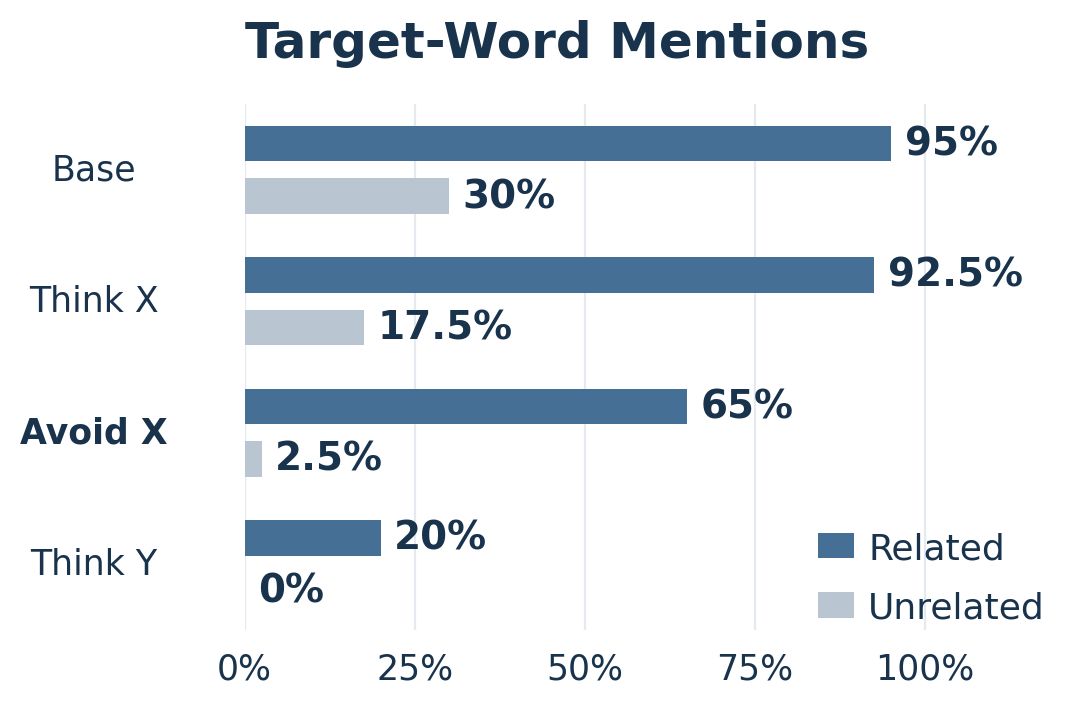

In [13]:

# === 3. Build a vector graphic ===

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Academic poster style: navy + muted blue-gray
NAVY = "#19334D"
BLUE = "#456F94"
GRAY = "#B9C5D0"
GRID = "#E5EAF0"

# Use the two-line condition labels defined in the settings cell.

plt.rcParams.update({
    "font.family": FONT,
    "svg.fonttype": "none",
    "axes.unicode_minus": False,
    "savefig.facecolor": "white",
})

fig, ax = plt.subplots(
    figsize=(FIGURE_WIDTH_CM / 2.54, FIGURE_HEIGHT_CM / 2.54),
    dpi=200,
    facecolor="white"
)

# Layout
fig.subplots_adjust(
    left=0.30,
    right=0.98,
    top=0.84,
    bottom=0.13
)

# Title
fig.text(
    0.30, 0.955,
    "Target-Word Mentions",
    fontsize=18,
    fontweight="bold",
    color=NAVY,
    ha="left",
    va="top"
)

# Legend
legend_handles = [
    mpatches.Patch(facecolor=BLUE, label="Related"),
    mpatches.Patch(facecolor=GRAY, label="Unrelated")
]

fig.legend(
    handles=legend_handles,
    loc="center right",
    bbox_to_anchor=(0.99, 0.2),
    bbox_transform=fig.transFigure,
    frameon=False,
    ncol=1,
    fontsize=13,
    handlelength=1.0,
    handletextpad=0.4,
    labelspacing=0.7,
    labelcolor=NAVY,
    borderaxespad=0
)

# Bars
centers = [3, 2, 1, 0]
offset = 0.20
bar_height = 0.27

for yi, condition in zip(centers, CONDITIONS):
    for cue, yy in [
        ("related", yi + offset),
        ("unrelated", yi - offset)
    ]:
        k, n = counts[condition][cue]
        value = 100 * k / n

        color = BLUE if cue == "related" else GRAY

        ax.barh(
            yy, value,
            height=bar_height,
            color=color,
            edgecolor="none",
            zorder=3
        )

        # Exact measured values
        ax.text(
            value + 2,
            yy,
            f"{value:g}%",
            fontsize=14,
            fontweight="bold",
            color=NAVY,
            ha="left",
            va="center",
            clip_on=False
        )

# Axes
ax.set_ylim(-0.5, 3.5)
ax.set_xlim(0, 118)


ax.set_yticks(centers)
ax.set_yticklabels(
    LABELS,
    fontsize=12.5,
    color=NAVY
)

# Keep each two-line label centered on its pair of bars.
for label in ax.get_yticklabels():

    label.set_horizontalalignment("center")
    label.set_multialignment("center")
    label.set_verticalalignment("center")
    label.set_x(-0.16)
    label.set_linespacing(1.15)

    if label.get_text().splitlines()[0] == "Avoid X":
        label.set_fontweight("bold")

ax.tick_params(axis="y", length=0, pad=8)


ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(
    ["0%", "25%", "50%", "75%", "100%"],
    fontsize=12.5,
    color=NAVY
)
ax.tick_params(axis="x", length=0, pad=8)

ax.grid(
    axis="x",
    color=GRID,
    linewidth=0.8,
    zorder=0
)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

# Export SVG and PNG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT_DIR / f"{OUTPUT_BASENAME}.svg",
    format="svg",
    dpi=300
)

fig.savefig(
    OUTPUT_DIR / f"{OUTPUT_BASENAME}.png",
    format="png",
    dpi=300
)

plt.show()


## Caption for the poster

**Fig. 2. Target-word mention rates under related and unrelated cues (one distractor block).** Each condition includes 40 generations across eight target concepts. The figure reports explicit word mentions, not hidden-state measurements.

**Notes for interpretation:** The suppression condition shows 65% for related cues but only 2.5% for unrelated cues; however, the Neutral condition is higher at 95% for related cues. The cue categories have **not** yet been calibrated into a continuous semantic-distance scale.

**Editing:** Set `FIGURE_WIDTH_CM` to the column width you will use in PowerPoint; the vector SVG retains editable text and crisp shapes. You can use `SOURCE_MODE='github_csv'` to reconstruct all rates from the original raw CSV when online, and switch back to `embedded` for reproducible offline rendering.
